# Challenge 2: K-Nearest Neighbors

Predict `Revenue` (did the visit end in a purchase?) with k-nearest neighbors, scikit-learn's `KNeighborsClassifier`. To score a visit, KNN finds the `k` most similar visits in the training data and uses the share of them that bought as the probability of purchase.

1. Load the data and make the same split as `challenge2_validation_split.ipynb` (same seed, so the same rows).
2. Prepare the features. KNN measures distance, so every input has to be on a similar scale.
3. Score a baseline and a default KNN.
4. Tune `k`, the weighting, and the distance measure with grid search on the 5 folds.
5. Pick the decision threshold that gives the best F1.
6. Evaluation charts.

The 20% hold-out is **not** used here. It gets scored once, after the team compares all models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (make_scorer, f1_score, precision_score, recall_score, confusion_matrix,
                             roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)

RANDOM_STATE = 42

In [2]:
# chart style used by every figure below
NAVY, ORANGE, TEAL, RED, GRAY = "#1f3b73", "#f28e2b", "#2a9d8f", "#d1495b", "#9aa0a6"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.frameon": False,
    "font.size": 10,
})

## Load and split

Same code and seed as `challenge2_validation_split.ipynb`, so these are the same training rows, hold-out rows and folds.

In [3]:
train = pd.read_csv("challenge2_train.csv")

def to_01(col):
    """Turn True/False (bool or text) into 1/0."""
    if col.dtype == bool:
        return col.astype(int)
    return col.astype(str).str.strip().str.lower().map({"true": 1, "false": 0})

y = to_01(train["Revenue"])
X = train.drop(columns=["ID", "Revenue"]).copy()
X["Weekend"] = to_01(X["Weekend"])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
BUYER_SHARE = y_train.mean()

print(f"Training rows: {len(X_train):,} ({BUYER_SHARE:.1%} buyers)")
print(f"Hold-out rows: {len(X_val):,} (not used in this notebook)")

Training rows: 7,397 (15.5% buyers)
Hold-out rows: 1,850 (not used in this notebook)


## Prepare the features

KNN compares visits by distance, so a column measured in thousands of seconds would decide every distance on its own. Everything goes through `StandardScaler`.

- **Long-tailed columns** (page counts, durations, `PageValues`): most visits are near zero and a few are huge. Taking `log(1 + x)` first pulls in the long tail, so a few extreme visits don't stretch the scale.
- **Rates** (`BounceRates`, `ExitRates`, `SpecialDay`): already between 0 and 1, so just scaled.
- **Category codes** (`Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`): one-hot encoded. `Browser 4` is not "twice" `Browser 2`.
- **`Weekend`**: already 0/1.

All of this sits inside the pipeline, so it is fitted on each fold's training rows only. This is the same preprocessing as the neural network notebook.

In [4]:
log_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "PageValues"]
rate_cols = ["BounceRates", "ExitRates", "SpecialDay"]
cat_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
bin_cols = ["Weekend"]

assert set(log_cols + rate_cols + cat_cols + bin_cols) == set(X.columns)

preprocessor = ColumnTransformer([
    ("log", Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), log_cols),
    ("rate", StandardScaler(), rate_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols),
])

print("Inputs to KNN:", preprocessor.fit_transform(X_train).shape[1])

Inputs to KNN: 72


## How models are scored

Only 15.5% of visits are purchases, so accuracy is misleading. The main score is **F1** (balances catching buyers against false alarms). Also reported:

- **ROC-AUC** and **PR-AUC**: how well the model ranks buyers above non-buyers, before any threshold is picked.
- **Recall**: share of real buyers caught. **Precision**: share of predicted buyers who really bought.
- **Train F1 and the gap**: a big gap between training and CV F1 means overfitting.

In [5]:
scoring = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "accuracy": "accuracy",
}

def evaluate(name, model):
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    row = {"model": name}
    for m in scoring:
        row[m] = res[f"test_{m}"].mean()
        row[f"{m} std"] = res[f"test_{m}"].std()
    row["train f1"] = res["train_f1"].mean()
    row["f1 gap"] = row["train f1"] - row["f1"]
    return row

SHOW = ["f1", "roc_auc", "pr_auc", "recall", "precision", "accuracy", "train f1", "f1 gap"]

results = [
    evaluate("Baseline (always 'no purchase')", DummyClassifier(strategy="most_frequent")),
    evaluate("KNN, default (k = 5)", KNeighborsClassifier()),
]
pd.DataFrame(results).set_index("model")[SHOW].round(3)

,f1,roc_auc,pr_auc,recall,precision,accuracy,train f1,f1 gap
model,,,,,,,,
Baseline (always 'no purchase'),0.000,0.500,0.155,0.000,0.000,0.845,0.000,0.000
"KNN, default (k = 5)",0.622,0.878,0.615,0.579,0.673,0.891,0.721,0.099


## Tune KNN

Settings searched:
- **`n_neighbors` (k)**: how many similar visits vote. Small `k` follows individual visits closely and can memorize noise (overfitting). Large `k` averages over many visits and can blur real patterns (underfitting).
- **`weights`**: `uniform` gives every neighbor one vote. `distance` gives closer neighbors more say.
- **`p`**: the distance measure. `p = 2` is ordinary straight-line distance. `p = 1` adds up the differences column by column, which is less thrown off by one very different column.

The search ranks settings by **ROC-AUC**, not F1. F1 depends on the 0.5 threshold, which is the wrong cut-off for rare buyers (fixed further down). ROC-AUC scores the ranking itself.

In [6]:
knn_pipe = Pipeline([("prep", preprocessor), ("model", KNeighborsClassifier())])

param_grid = {
    "model__n_neighbors": [5, 11, 21, 31, 51, 75, 101, 151],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}

search = GridSearchCV(knn_pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train)

best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print("Best settings:", best_params)
print(f"Best CV ROC-AUC: {search.best_score_:.3f}")

Best settings: {'n_neighbors': 51, 'p': 2, 'weights': 'distance'}
Best CV ROC-AUC: 0.922


In [7]:
grid = pd.DataFrame(search.cv_results_)
grid["k"] = grid["param_model__n_neighbors"].astype(int)
grid["weights"] = grid["param_model__weights"].astype(str)
grid["p"] = grid["param_model__p"].astype(int)

grid.sort_values("rank_test_score").head(10)[
    ["k", "weights", "p", "mean_test_score", "mean_train_score"]
].rename(columns={"mean_test_score": "CV ROC-AUC", "mean_train_score": "train ROC-AUC"}).round(4).reset_index(drop=True)

,k,weights,p,CV ROC-AUC,train ROC-AUC
0,51,distance,2,0.9223,1.0000
1,75,distance,2,0.9223,1.0000
2,51,uniform,2,0.9211,0.9341
3,101,distance,2,0.9211,1.0000
4,75,uniform,2,0.9211,0.9306
5,151,distance,2,0.9203,1.0000
6,31,distance,2,0.9199,1.0000
7,101,uniform,2,0.9198,0.9277
8,151,uniform,2,0.9190,0.9241
9,31,uniform,2,0.9187,0.9387


With `weights = "distance"`, every training visit is its own closest neighbor at distance zero, so the training score is always perfect. For those settings, the train score says nothing about overfitting. Compare CV scores instead.

In [8]:
best_knn = KNeighborsClassifier(**best_params)
best_pipe = Pipeline([("prep", preprocessor), ("model", best_knn)])

results.append(evaluate(f"KNN, tuned (k = {best_params['n_neighbors']})", best_knn))
pd.DataFrame(results).set_index("model")[SHOW].round(3)

,f1,roc_auc,pr_auc,recall,precision,accuracy,train f1,f1 gap
model,,,,,,,,
Baseline (always 'no purchase'),0.000,0.500,0.155,0.000,0.000,0.845,0.000,0.000
"KNN, default (k = 5)",0.622,0.878,0.615,0.579,0.673,0.891,0.721,0.099
"KNN, tuned (k = 51)",0.626,0.922,0.735,0.551,0.725,0.898,1.000,0.374


## Out-of-fold predictions

Every training row gets a purchase probability from a model that did **not** train on it: for each of the 5 folds, fit on the other 4 and predict that fold. All charts below and the threshold choice use these predictions, never the hold-out.

In [9]:
oof_proba = np.zeros(len(y_train))
fold_id = np.zeros(len(y_train), dtype=int)
fold_models = []

for k, (tr, va) in enumerate(cv.split(X_train, y_train), 1):
    m = clone(best_pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
    oof_proba[va] = m.predict_proba(X_train.iloc[va])[:, 1]
    fold_id[va] = k
    fold_models.append((m, va))

y_true = y_train.to_numpy()
print(f"Out-of-fold ROC-AUC: {roc_auc_score(y_true, oof_proba):.3f}")
print(f"Out-of-fold PR-AUC:  {average_precision_score(y_true, oof_proba):.3f}")

Out-of-fold ROC-AUC: 0.922
Out-of-fold PR-AUC:  0.731


## Pick the decision threshold

KNN's probability is the (weighted) share of neighbors that bought. By default a visit counts as "buyer" when that share is at least 0.5. With only 15.5% buyers, many real buyers have fewer than half buying neighbors, so a lower cut-off usually gives a better F1. Every threshold from 0.05 to 0.95 is tried on the out-of-fold predictions and the best F1 is kept.

The tuned threshold is picked and scored on the same predictions, so its F1 is slightly optimistic. The hold-out score at the end will be the honest number.

In [10]:
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
curve = pd.DataFrame({
    "threshold": thresholds,
    "f1": [f1_score(y_true, oof_proba >= t) for t in thresholds],
    "precision": [precision_score(y_true, oof_proba >= t, zero_division=0) for t in thresholds],
    "recall": [recall_score(y_true, oof_proba >= t) for t in thresholds],
})
best_threshold = curve.loc[curve["f1"].idxmax(), "threshold"]

def scores_at(t):
    pred = oof_proba >= t
    return {"threshold": t, "f1": f1_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "accuracy": (pred == y_true).mean()}

pd.DataFrame([scores_at(0.5), scores_at(best_threshold)], index=["default", "tuned"]).round(3)

,threshold,f1,precision,recall,accuracy
default,0.50,0.626,0.724,0.551,0.898
tuned,0.34,0.679,0.639,0.724,0.894


---
# Evaluation charts

### 1. Model comparison

Accuracy (far right) is the trap: the baseline that never predicts a purchase already scores about 85%. The other scores show the real difference. Error bars are the spread across the 5 folds.

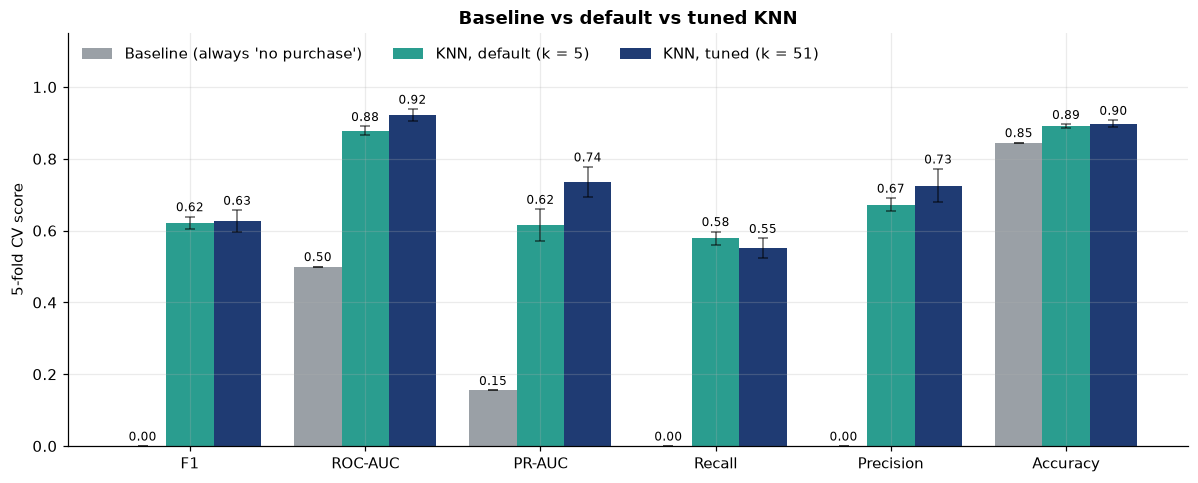

In [11]:
res = pd.DataFrame(results).set_index("model")
metrics = ["f1", "roc_auc", "pr_auc", "recall", "precision", "accuracy"]
labels = ["F1", "ROC-AUC", "PR-AUC", "Recall", "Precision", "Accuracy"]
colors = [GRAY, TEAL, NAVY]

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(metrics))
w = 0.27
for i, (name, row) in enumerate(res.iterrows()):
    vals = [row[m] for m in metrics]
    errs = [row[f"{m} std"] for m in metrics]
    ax.bar(x + (i - 1) * w, vals, w, yerr=errs, capsize=3, color=colors[i], label=name,
           error_kw={"elinewidth": 1, "alpha": 0.6})
    for xi, v, e in zip(x + (i - 1) * w, vals, errs):
        ax.text(xi, v + e + 0.015, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, labels)
ax.set_ylim(0, 1.15)
ax.set_ylabel("5-fold CV score")
ax.set_title("Baseline vs default vs tuned KNN")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout()
plt.show()

### 2. Tuning results

Each cell is the CV ROC-AUC for one `k` and one weighting, using the best distance measure. Dark is better. The black box is the setting chosen.

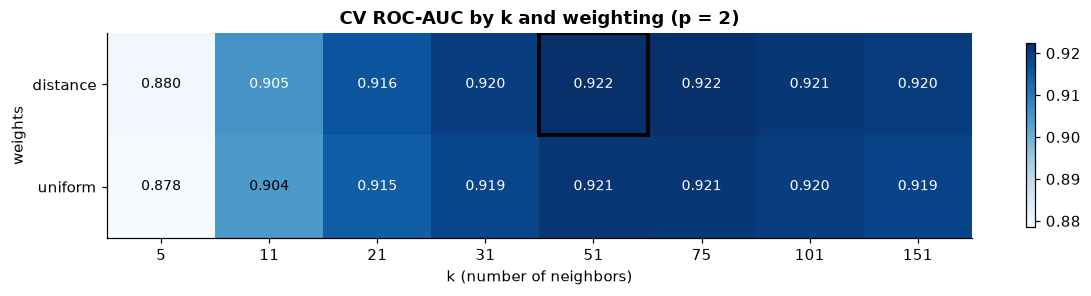

In [12]:
best_p = best_params["p"]
heat = (grid[grid["p"] == best_p]
        .pivot_table(index="weights", columns="k", values="mean_test_score"))

fig, ax = plt.subplots(figsize=(11, 2.8))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.grid(False)
lo, hi = np.nanmin(heat.values), np.nanmax(heat.values)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                color="white" if v > lo + 0.6 * (hi - lo) else "black")
bi = list(heat.index).index(best_params["weights"])
bj = list(heat.columns).index(best_params["n_neighbors"])
ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=2.5))
ax.set_xlabel("k (number of neighbors)")
ax.set_ylabel("weights")
ax.set_title(f"CV ROC-AUC by k and weighting (p = {best_p})")
fig.colorbar(im, ax=ax, shrink=0.9)
plt.tight_layout()
plt.show()

### 3. Underfitting vs overfitting across `k`

Training vs CV ROC-AUC with `uniform` weights, where the training score is meaningful. With small `k` the training score is far above CV: each visit is mostly judged by itself and its closest copies, so KNN memorizes. As `k` grows the two lines meet. If `k` gets too large, CV starts to fall because the vote averages over visits that aren't really similar (underfitting).

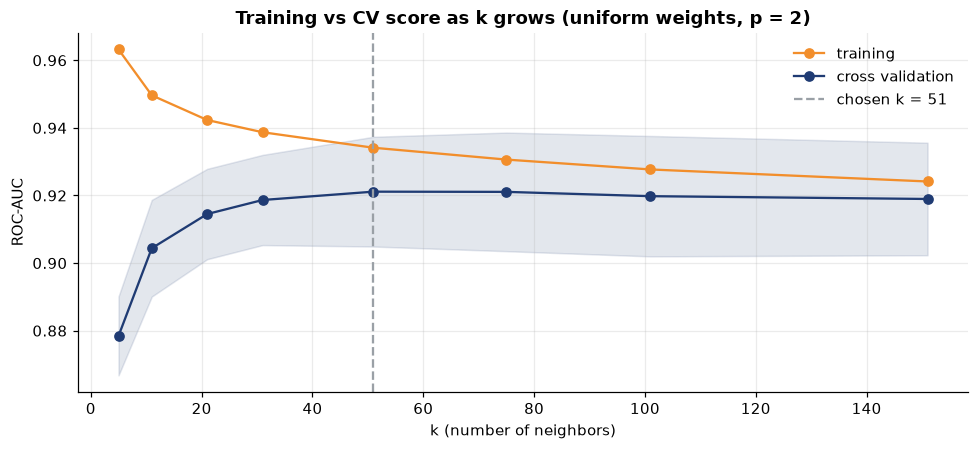

In [13]:
sub = grid[(grid["p"] == best_p) & (grid["weights"] == "uniform")].sort_values("k")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(sub["k"], sub["mean_train_score"], "o-", color=ORANGE, label="training")
ax.plot(sub["k"], sub["mean_test_score"], "o-", color=NAVY, label="cross validation")
ax.fill_between(sub["k"], sub["mean_test_score"] - sub["std_test_score"],
                sub["mean_test_score"] + sub["std_test_score"], color=NAVY, alpha=0.12)
ax.axvline(best_params["n_neighbors"], color=GRAY, linestyle="--", label=f"chosen k = {best_params['n_neighbors']}")
ax.set_xlabel("k (number of neighbors)")
ax.set_ylabel("ROC-AUC")
ax.set_title(f"Training vs CV score as k grows (uniform weights, p = {best_p})")
ax.legend()
plt.tight_layout()
plt.show()

### 4. ROC and precision-recall curves

Thin lines are the 5 folds, the thick line is all out-of-fold predictions together. The dot is the chosen threshold.

- **ROC**: the dashed diagonal is random guessing.
- **Precision-recall**: more useful when buyers are rare. The dashed line is the 15.5% buyer share, which is what random guessing gets.

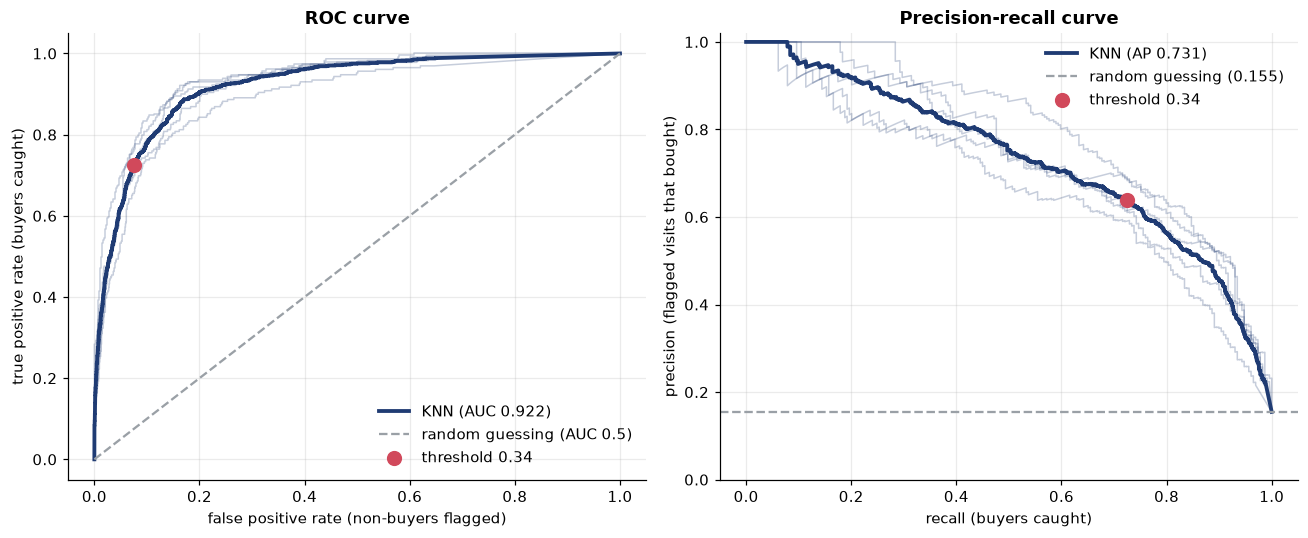

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
pred_best = oof_proba >= best_threshold
tpr_pt = recall_score(y_true, pred_best)
fpr_pt = ((pred_best == 1) & (y_true == 0)).sum() / (y_true == 0).sum()
prec_pt = precision_score(y_true, pred_best)

for k in range(1, 6):
    m = fold_id == k
    fpr, tpr, _ = roc_curve(y_true[m], oof_proba[m])
    ax1.plot(fpr, tpr, color=NAVY, alpha=0.25, linewidth=1)
    p, r, _ = precision_recall_curve(y_true[m], oof_proba[m])
    ax2.plot(r, p, color=NAVY, alpha=0.25, linewidth=1)

fpr, tpr, _ = roc_curve(y_true, oof_proba)
ax1.plot(fpr, tpr, color=NAVY, linewidth=2.5, label=f"KNN (AUC {roc_auc_score(y_true, oof_proba):.3f})")
ax1.plot([0, 1], [0, 1], "--", color=GRAY, label="random guessing (AUC 0.5)")
ax1.scatter([fpr_pt], [tpr_pt], s=80, color=RED, zorder=5, label=f"threshold {best_threshold:.2f}")
ax1.set_xlabel("false positive rate (non-buyers flagged)")
ax1.set_ylabel("true positive rate (buyers caught)")
ax1.set_title("ROC curve")
ax1.legend(loc="lower right")

p, r, _ = precision_recall_curve(y_true, oof_proba)
ax2.plot(r, p, color=NAVY, linewidth=2.5, label=f"KNN (AP {average_precision_score(y_true, oof_proba):.3f})")
ax2.axhline(BUYER_SHARE, linestyle="--", color=GRAY, label=f"random guessing ({BUYER_SHARE:.3f})")
ax2.scatter([tpr_pt], [prec_pt], s=80, color=RED, zorder=5, label=f"threshold {best_threshold:.2f}")
ax2.set_xlabel("recall (buyers caught)")
ax2.set_ylabel("precision (flagged visits that bought)")
ax2.set_ylim(0, 1.02)
ax2.set_title("Precision-recall curve")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 5. Choosing the threshold

Lowering the threshold catches more buyers (recall up) but flags more non-buyers (precision down). F1 balances the two and peaks at the chosen threshold.

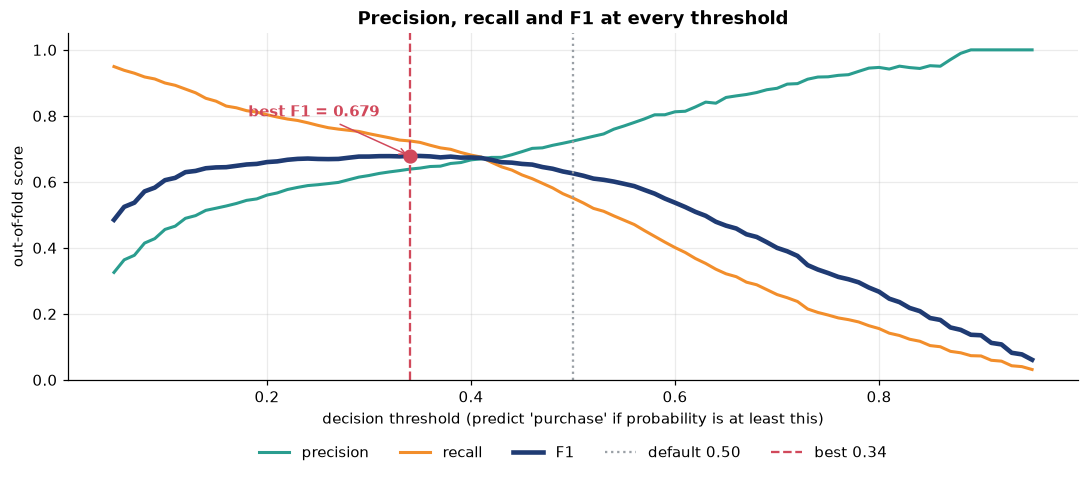

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(curve["threshold"], curve["precision"], color=TEAL, linewidth=2, label="precision")
ax.plot(curve["threshold"], curve["recall"], color=ORANGE, linewidth=2, label="recall")
ax.plot(curve["threshold"], curve["f1"], color=NAVY, linewidth=3, label="F1")
ax.axvline(0.5, color=GRAY, linestyle=":", label="default 0.50")
ax.axvline(best_threshold, color=RED, linestyle="--", label=f"best {best_threshold:.2f}")
best_f1 = curve["f1"].max()
ax.scatter([best_threshold], [best_f1], s=70, color=RED, zorder=5)
ax.annotate(f"best F1 = {best_f1:.3f}", xy=(best_threshold, best_f1), xytext=(best_threshold - 0.03, best_f1 + 0.12),
            ha="right", arrowprops={"arrowstyle": "->", "color": RED}, color=RED, fontweight="bold")
ax.set_xlabel("decision threshold (predict 'purchase' if probability is at least this)")
ax.set_ylabel("out-of-fold score")
ax.set_ylim(0, 1.05)
ax.set_title("Precision, recall and F1 at every threshold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5)
plt.tight_layout()
plt.show()

### 6. Confusion matrices

Counts and, in brackets, the share of each true class. The top row is non-buyers, the bottom row is buyers. The lower threshold catches more buyers (bottom right) at the cost of more false alarms (top right).

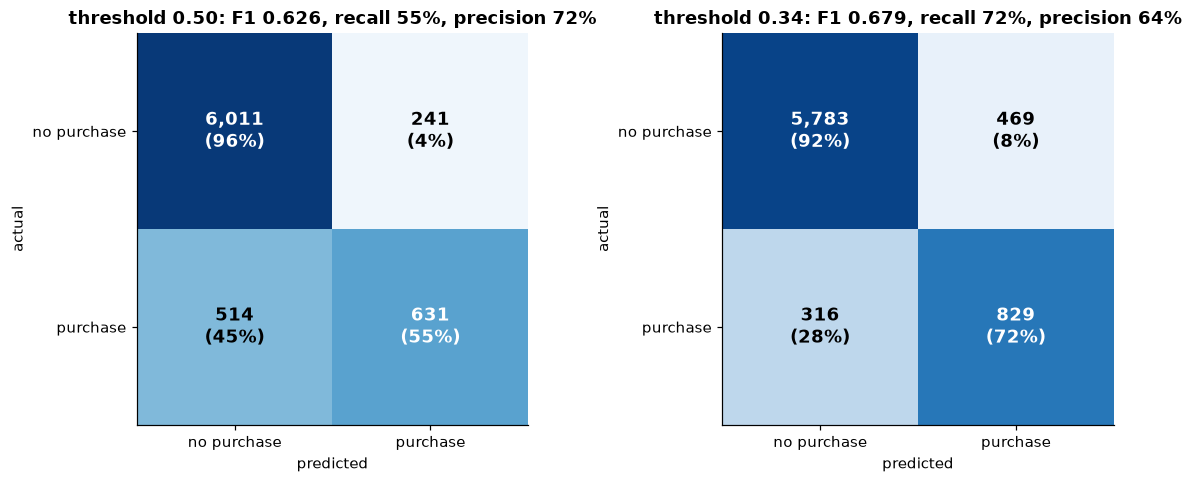

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
names = ["no purchase", "purchase"]
for ax, t in zip(axes, [0.5, best_threshold]):
    cm = confusion_matrix(y_true, oof_proba >= t)
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({share[i, j]:.0%})", ha="center", va="center", fontsize=12,
                    color="white" if share[i, j] > 0.5 else "black", fontweight="bold")
    ax.set_xticks([0, 1], names)
    ax.set_yticks([0, 1], names)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    s = scores_at(t)
    ax.set_title(f"threshold {t:.2f}: F1 {s['f1']:.3f}, recall {s['recall']:.0%}, precision {s['precision']:.0%}")
plt.tight_layout()
plt.show()

### 7. How confident is KNN?

Predicted purchase probability for real non-buyers (top) and real buyers (bottom). A good model pushes non-buyers toward 0 and buyers toward 1. Red bars are the mistakes at the chosen threshold: non-buyers flagged as buyers, and buyers that were missed.

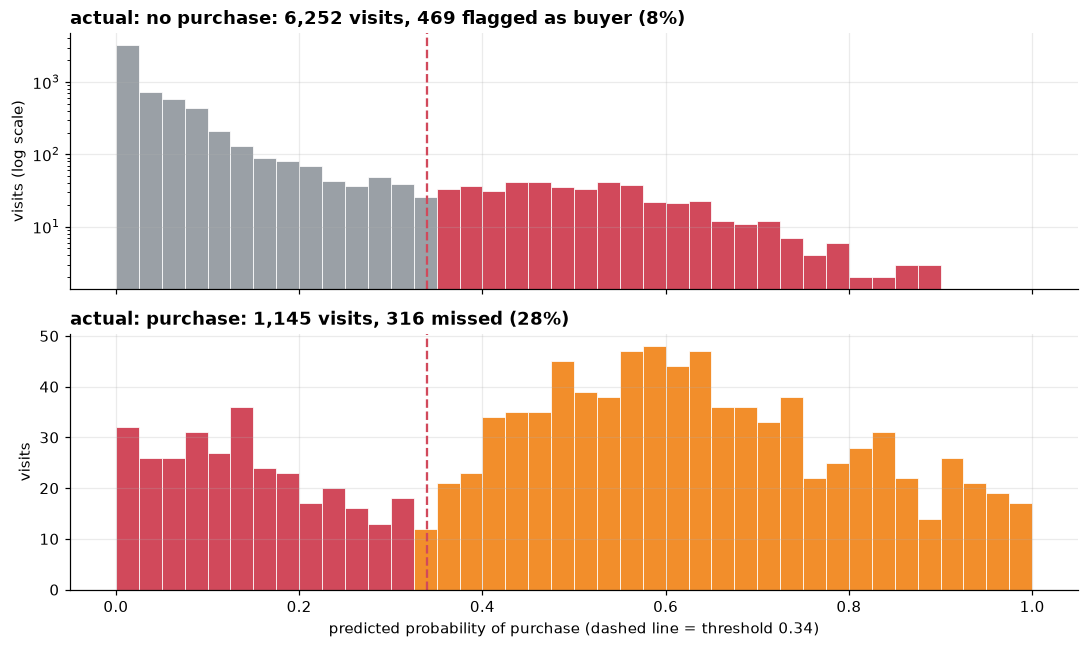

In [17]:
bins = np.linspace(0, 1, 41)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
groups = [(0, "actual: no purchase", GRAY, "flagged as buyer"), (1, "actual: purchase", ORANGE, "missed")]
for ax, (cls, title, color, wrong_label) in zip(axes, groups):
    p = oof_proba[y_true == cls]
    counts, edges = np.histogram(p, bins=bins)
    wrong = (edges[:-1] >= best_threshold) if cls == 0 else (edges[1:] <= best_threshold)
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color=np.where(wrong, RED, color),
           edgecolor="white", linewidth=0.5)
    ax.axvline(best_threshold, color=RED, linestyle="--", linewidth=1.5)
    n_wrong = (p >= best_threshold).sum() if cls == 0 else (p < best_threshold).sum()
    ax.set_title(f"{title}: {len(p):,} visits, {n_wrong:,} {wrong_label} ({n_wrong / len(p):.0%})", loc="left")
    ax.set_ylabel("visits")
axes[0].set_yscale("log")
axes[0].set_ylabel("visits (log scale)")
axes[1].set_xlabel(f"predicted probability of purchase (dashed line = threshold {best_threshold:.2f})")
plt.tight_layout()
plt.show()

### 8. Calibration

When KNN says "30% chance of purchase", do about 30% of those visits buy? Points on the dashed diagonal mean the probabilities can be taken at face value. Visits are grouped into 10 equal-width probability ranges, and bigger dots hold more visits.

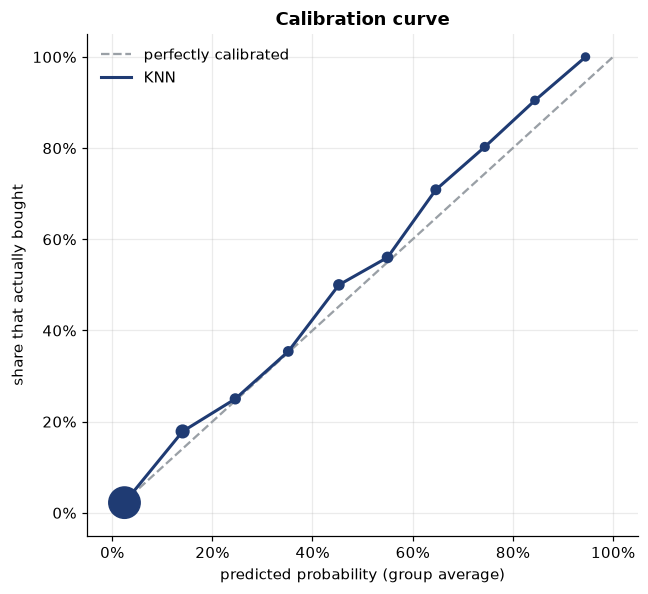

In [18]:
frac_pos, mean_pred = calibration_curve(y_true, oof_proba, n_bins=10, strategy="uniform")
bin_counts = np.histogram(oof_proba, bins=np.linspace(0, 1, 11))[0]
bin_counts = bin_counts[bin_counts > 0]

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([0, 1], [0, 1], "--", color=GRAY, label="perfectly calibrated")
ax.plot(mean_pred, frac_pos, "-", color=NAVY, linewidth=2, label="KNN")
ax.scatter(mean_pred, frac_pos, s=20 + 400 * bin_counts / bin_counts.max(), color=NAVY, zorder=5)
ax.set_xlabel("predicted probability (group average)")
ax.set_ylabel("share that actually bought")
ax.set_title("Calibration curve")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 9. Learning curve

CV ROC-AUC as KNN gets more training rows to search through. KNN has no training step, so more rows simply means more possible neighbors. If the line is still rising at the right, more data would help.

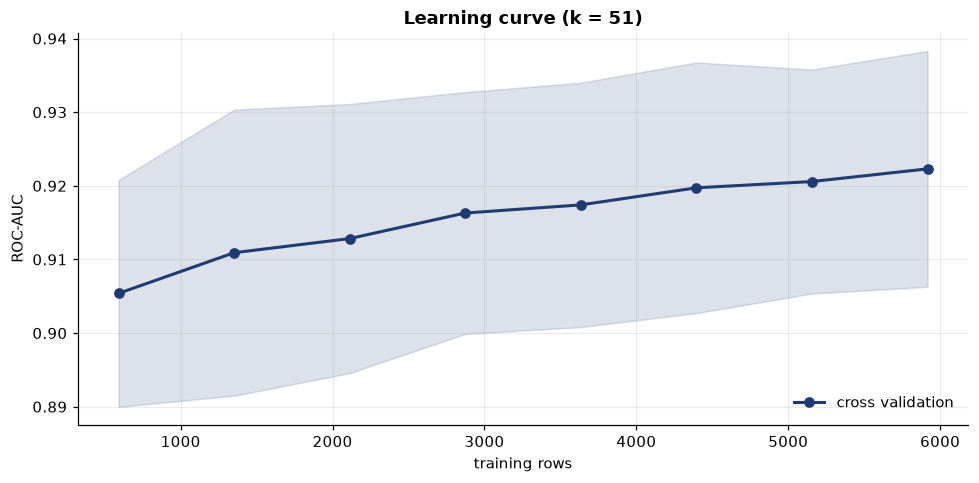

In [19]:
sizes, tr_scores, cv_scores = learning_curve(
    best_pipe, X_train, y_train, cv=cv, scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, shuffle=True, random_state=RANDOM_STATE,
)

fig, ax = plt.subplots(figsize=(9, 4.5))
mean, std = cv_scores.mean(axis=1), cv_scores.std(axis=1)
ax.plot(sizes, mean, "o-", color=NAVY, linewidth=2, label="cross validation")
ax.fill_between(sizes, mean - std, mean + std, color=NAVY, alpha=0.15)
ax.set_xlabel("training rows")
ax.set_ylabel("ROC-AUC")
ax.set_title(f"Learning curve (k = {best_params['n_neighbors']})")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 10. What KNN relies on

KNN has no coefficients to read, so this uses **permutation importance**: shuffle one column in a fold's scoring rows and measure how much ROC-AUC drops. A big drop means the distances lean on that column. Averaged over the 5 folds, using each fold's own model.

/opt/anaconda3/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


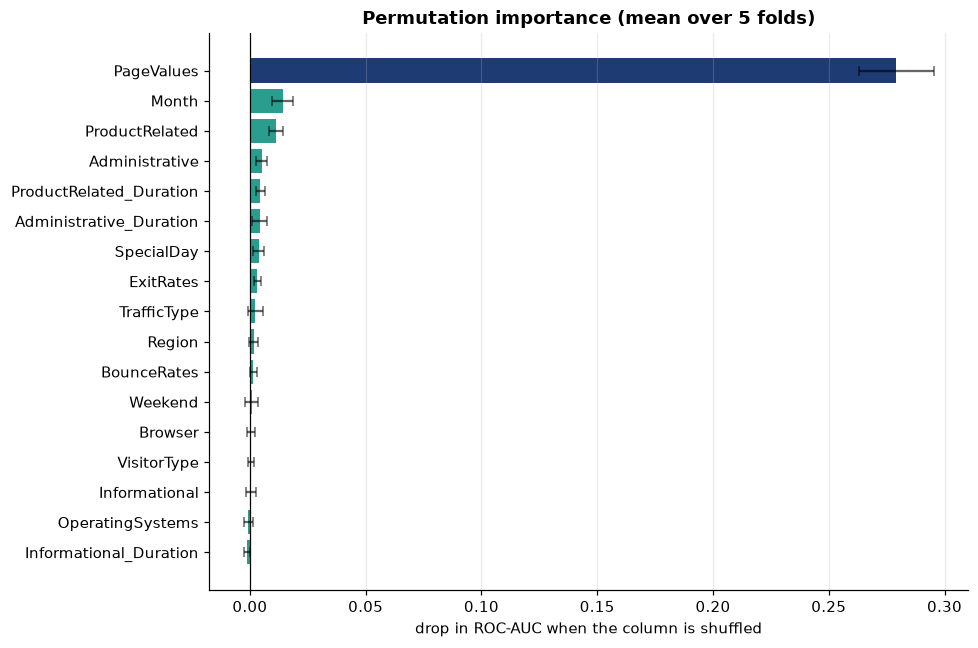

In [20]:
drops = []
for m, va in fold_models:
    pi = permutation_importance(m, X_train.iloc[va], y_train.iloc[va], scoring="roc_auc",
                                n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
    drops.append(pi.importances_mean)
drops = pd.DataFrame(drops, columns=X_train.columns)
imp = pd.DataFrame({"mean": drops.mean(), "std": drops.std()}).sort_values("mean")

fig, ax = plt.subplots(figsize=(9, 6))
colors = [NAVY if c == imp.index[-1] else TEAL for c in imp.index]
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color=colors, capsize=3, error_kw={"alpha": 0.6})
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("drop in ROC-AUC when the column is shuffled")
ax.set_title("Permutation importance (mean over 5 folds)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Who gets missed?

Most visits with `PageValues = 0` never buy, so a buyer with `PageValues = 0` has mostly non-buyers as neighbors.

In [21]:
pv_zero = (X_train["PageValues"] == 0).to_numpy()
missed = (y_true == 1) & (oof_proba < best_threshold)

print(f"Buy rate when PageValues = 0: {y_true[pv_zero].mean():.1%}")
print(f"Buy rate when PageValues > 0: {y_true[~pv_zero].mean():.1%}")
print(f"Missed buyers: {missed.sum():,}, of which {(missed & pv_zero).sum():,} "
      f"({(missed & pv_zero).sum() / missed.sum():.0%}) have PageValues = 0")

Buy rate when PageValues = 0: 3.5%
Buy rate when PageValues > 0: 57.8%
Missed buyers: 316, of which 201 (64%) have PageValues = 0


---
## Takeaways

- **KNN beats the baseline clearly.** CV ROC-AUC 0.92 and PR-AUC 0.73, compared with 0.50 and 0.15 for always guessing "no purchase".
- **`k` matters most.** The default `k = 5` scores 0.878 ROC-AUC. CV rises quickly up to about `k = 31` and is flat from 51 to 151. The chosen setting is `k = 51`, closer neighbors weighted more (`distance`), straight-line distance (`p = 2`). Weighting barely matters (0.922 vs 0.921 for `uniform`).
- **Lowering the threshold to 0.34 raises F1 from 0.63 to 0.68.** It catches 72% of buyers instead of 55%, while 64% of flagged visits really buy (down from 72%).
- **Overfitting:** with `uniform` weights, small `k` overfits (training 0.96 vs CV 0.88 at `k = 5`), and the gap closes as `k` grows. The tuned model's training score is a perfect 1.0 only because `distance` weighting always finds each visit itself, so that number is not a fair overfitting check.
- **More data would still help a little.** The learning curve is still rising slowly at the full training size.
- **`PageValues` does most of the work**, as with the other models. 64% of the buyers KNN misses have `PageValues = 0`.
- **Compared with the other models so far,** KNN ranks a bit lower than the neural network (0.932) and gradient boosting (0.937) on ROC-AUC, and above the SVM (0.912).


---
## Summary for the team comparison

In [22]:
tuned = pd.DataFrame(results).set_index("model").iloc[-1]
at_t = scores_at(best_threshold)

summary = pd.Series({
    "settings": str(best_params),
    "CV ROC-AUC": round(tuned["roc_auc"], 3),
    "CV PR-AUC": round(tuned["pr_auc"], 3),
    "CV F1 @ 0.5": round(tuned["f1"], 3),
    "train F1 @ 0.5": round(tuned["train f1"], 3),
    "best threshold": best_threshold,
    "CV F1 @ best threshold": round(at_t["f1"], 3),
    "recall @ best threshold": round(at_t["recall"], 3),
    "precision @ best threshold": round(at_t["precision"], 3),
}, name="K-Nearest Neighbors")
summary.to_frame()

,K-Nearest Neighbors
settings,"{'n_neighbors': 51, 'p': 2, 'weights': 'distan..."
CV ROC-AUC,0.922
CV PR-AUC,0.735
CV F1 @ 0.5,0.626
train F1 @ 0.5,1.0
best threshold,0.34
CV F1 @ best threshold,0.679
recall @ best threshold,0.724
precision @ best threshold,0.639
